# Stage 4 + 5b + 6 — Feature Engineering, Modelling & Evaluation

**Notebook 5 of 6** · Governed by `DOCS/STRUCTURE.md` Stages 4, 5b, 6 and Cross-Cutting

---

## What this notebook is for

Stage 5a established *which measurements associate with disease*. This notebook answers the
second half of the business question: **once the file's 70% duplication and its
angiography-derived features are removed, how well can a classifier actually separate the
classes?**

It runs in four movements:

| § | Movement | Why it comes in this order |
|---|---|---|
| 5b.0 | **The leakage experiment** | Runs *first*, before any real modelling, because it defines what every subsequent number means. |
| 4 | **Feature engineering + ablation** | Derived features are *tested*, not assumed useful — at n = 302 they are as likely to add variance as signal. |
| 5b | **Model zoo, two scopes** | Simple → complex, Scope 1 (pre-test) and Scope 2 (post-catheterisation) side by side. |
| 6 | **Evaluation, calibration, fairness** | Operating point chosen for the cost asymmetry; the mandatory subgroup audit Stage 1 scheduled. |

### The two scopes — the analytical spine of this project

| Scope | Features | The question it can answer | Status |
|---|---|---|---|
| **Scope 1 — pre-test** | 11 features, branches A–D | *Given history, resting workup and a stress test, how likely is angiographic disease?* — answerable **before** the catheter | **Primary.** Carries the recommendation. |
| **Scope 2 — post-catheterisation** | all 13 (adds `ca`, `thal`) | *How well do the classes separate when label-adjacent measurements are allowed in?* | **Comparator only.** Its lift over Scope 1 prices the circularity. |

`ca` (vessels coloured by fluoroscopy) and `thal` (thallium perfusion) are produced by the same
catheterisation workup that *defines* `target`. A model containing them cannot answer "who should
we send to angiography" — it already knows the answer.

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

ROOT = Path.cwd() if (Path.cwd() / "heart.csv").exists() else Path.cwd().parent
PROC_DIR = ROOT / "data" / "processed"
REP_DIR = ROOT / "reports"
FIG_DIR = REP_DIR / "figures"
MODEL_DIR = ROOT / "models"
for d in (FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

# --- DOCS/DESIGN.md palette, inline (no local imports - a fresh clone must run)
NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
CYAN, AMBER = "#00A9F4", "#C1841C"
SLATE, GREY, GRID = "#7F93A6", "#9FADB8", "#E9ECEF"
C_HONEST, C_CONTAM, C_REF = BLUE, GREY, AMBER


def apply_mck_style():
    mpl.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"], "font.size": 9.5,
        "text.color": NAVY, "axes.labelcolor": NAVY, "axes.labelsize": 9,
        "axes.edgecolor": GRID, "axes.linewidth": 0.9,
        "xtick.color": SLATE, "ytick.color": SLATE,
        "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "xtick.major.size": 0, "ytick.major.size": 0,
        "axes.titlelocation": "left", "axes.titlesize": 10, "axes.titleweight": "bold",
        "axes.titlepad": 10, "axes.titlecolor": NAVY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
        "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "figure.dpi": 110, "savefig.dpi": 200,
        "savefig.bbox": "tight", "savefig.facecolor": "white",
    })


apply_mck_style()


def save_exhibit(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print(f"saved reports/figures/{name}.png")


def source_note(fig, text, y=-0.05):
    fig.text(0.02, y, text, fontsize=7.5, color=SLATE, ha="left")


def boot_ci(fn, *arrays, n_boot=2000, seed=RANDOM_STATE):
    """Percentile bootstrap CI for any metric fn(y_true, y_score)."""
    r = np.random.default_rng(seed)
    n = len(arrays[0])
    stats = []
    for _ in range(n_boot):
        idx = r.integers(0, n, n)
        if len(np.unique(arrays[0][idx])) < 2:
            continue
        stats.append(fn(*[a[idx] for a in arrays]))
    return float(np.percentile(stats, 2.5)), float(np.percentile(stats, 97.5))


df = pd.read_parquet(PROC_DIR / "heart_clean.parquet")
raw = pd.read_csv(ROOT / "data" / "raw" / "heart.csv")

SCOPE1 = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
          "thalach", "exang", "oldpeak", "slope"]
SCOPE2_ONLY = ["ca", "thal"]
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
NOMINAL = ["cp", "restecg"]

print(f"clean cohort : {len(df)} patients · {int(df.target.sum())} disease / "
      f"{int((1 - df.target).sum())} no disease")
print(f"raw file     : {len(raw):,} rows (retained only as the contaminated comparator)")

clean cohort : 302 patients · 164 disease / 138 no disease
raw file     : 1,025 rows (retained only as the contaminated comparator)


## 5b.0 The leakage experiment

**This runs before any real modelling, because it determines what every later number means.**

The published literature on this exact file routinely reports 95–100% accuracy. The question is
whether any of that is real. Three protocols, **identical model and identical feature set**
(all 13 features, as the benchmarks use), varying only *how the data is split*:

| Protocol | Data | Split | What it represents |
|---|---|---|---|
| **P1 — Contaminated holdout** | 1,025 rows | stratified 80/20 | what most published benchmarks do |
| **P2 — Contaminated CV** | 1,025 rows | stratified 10-fold | the "more rigorous" version — still contaminated |
| **P3 — Honest** | 302 patients | repeated stratified 10-fold × 5 | the real number |

Holding features and model constant isolates a single variable: **duplication**.

In [2]:
# Deterministic, row-wise placeholder recoding - identical rule applied to both files.
# No statistic is fitted here, so this cannot leak.
def recode(frame):
    out = frame.copy()
    out["ca"] = out["ca"].replace(4, np.nan)
    out["thal"] = out["thal"].replace(0, np.nan)
    # Explicit 'unknown' handling: sentinel for the ordinal, own level for the nominal
    out["ca_s"] = out["ca"].fillna(-1.0)
    out["thal_c"] = out["thal"].map({1: "normal", 2: "fixed", 3: "reversible"}).fillna("unknown")
    return out


raw_r, clean_r = recode(raw), recode(df)

ALL13 = SCOPE1 + ["ca_s", "thal_c"]


def make_pipe(model, features, scale=True):
    """One ColumnTransformer contract used everywhere: scale numerics, one-hot nominals."""
    num = [c for c in features if c in NUMERIC]
    nom = [c for c in features if c in NOMINAL + ["thal_c"]]
    rest = [c for c in features if c not in num + nom]
    steps = [
        ("num", StandardScaler() if scale else "passthrough", num),
        ("nom", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), nom),
        ("rest", StandardScaler() if scale else "passthrough", rest),
    ]
    return Pipeline([("prep", ColumnTransformer(steps)), ("clf", model)])


LR = lambda: LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
RF = lambda: RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)

In [3]:
# How much of a contaminated test set is memorisation rather than generalisation?
Xr, yr = raw_r[ALL13], raw_r["target"].to_numpy()
tr_idx, te_idx = train_test_split(np.arange(len(raw_r)), test_size=0.2,
                                  stratify=yr, random_state=RANDOM_STATE)

key_cols = list(raw.columns)
train_keys = set(map(tuple, raw.iloc[tr_idx][key_cols].to_numpy()))
test_keys = list(map(tuple, raw.iloc[te_idx][key_cols].to_numpy()))
twin_share = np.mean([k in train_keys for k in test_keys])

print(f"P1 test set size                                   : {len(te_idx)} rows")
print(f"test rows whose EXACT twin sits in the training set: "
      f"{int(twin_share * len(te_idx))} ({twin_share:.1%})")
print("\n-> the 'test set' is overwhelmingly a memorisation check, not a generalisation check.")

P1 test set size                                   : 205 rows
test rows whose EXACT twin sits in the training set: 202 (98.5%)

-> the 'test set' is overwhelmingly a memorisation check, not a generalisation check.


In [4]:
results_leak = []
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
cv_honest = RepeatedStratifiedKFold(n_splits=10, n_repeats=5, random_state=RANDOM_STATE)
Xc, yc = clean_r[ALL13], clean_r["target"].to_numpy()

for name, mk in [("Logistic regression", LR), ("Random forest", RF)]:
    # P1 - contaminated holdout
    p = make_pipe(mk(), ALL13).fit(Xr.iloc[tr_idx], yr[tr_idx])
    pr = p.predict_proba(Xr.iloc[te_idx])[:, 1]
    results_leak.append({"model": name, "protocol": "P1 contaminated holdout", "n": len(raw_r),
                         "accuracy": accuracy_score(yr[te_idx], (pr >= .5).astype(int)),
                         "roc_auc": roc_auc_score(yr[te_idx], pr), "auc_std": np.nan})

    # P2 - contaminated 10-fold CV
    cv = cross_validate(make_pipe(mk(), ALL13), Xr, yr, cv=cv10,
                        scoring=["accuracy", "roc_auc"], n_jobs=-1)
    results_leak.append({"model": name, "protocol": "P2 contaminated 10-fold CV", "n": len(raw_r),
                         "accuracy": cv["test_accuracy"].mean(),
                         "roc_auc": cv["test_roc_auc"].mean(), "auc_std": cv["test_roc_auc"].std()})

    # P3 - honest, deduplicated, repeated CV
    cv = cross_validate(make_pipe(mk(), ALL13), Xc, yc, cv=cv_honest,
                        scoring=["accuracy", "roc_auc"], n_jobs=-1)
    results_leak.append({"model": name, "protocol": "P3 honest (302, repeated CV)", "n": len(clean_r),
                         "accuracy": cv["test_accuracy"].mean(),
                         "roc_auc": cv["test_roc_auc"].mean(), "auc_std": cv["test_roc_auc"].std()})

leak = pd.DataFrame(results_leak)
display(leak.round(4))

rf_gap_auc = (leak.query("model == 'Random forest' and protocol.str.startswith('P1')")["roc_auc"].iat[0]
              - leak.query("model == 'Random forest' and protocol.str.startswith('P3')")["roc_auc"].iat[0])
rf_gap_acc = (leak.query("model == 'Random forest' and protocol.str.startswith('P1')")["accuracy"].iat[0]
              - leak.query("model == 'Random forest' and protocol.str.startswith('P3')")["accuracy"].iat[0])
print(f"\nRandom forest, contaminated - honest:  "
      f"AUC +{rf_gap_auc:.3f}   accuracy +{rf_gap_acc:.1%}")

,model,protocol,n,accuracy,roc_auc,auc_std
0,Logistic regression,P1 contaminated holdout,1025,0.8634,0.9368,NaN
1,Logistic regression,P2 contaminated 10-fold CV,1025,0.8623,0.9332,0.0272
2,Logistic regression,"P3 honest (302, repeated CV)",302,0.8417,0.9098,0.0572
3,Random forest,P1 contaminated holdout,1025,1.0000,1.0000,NaN
4,Random forest,P2 contaminated 10-fold CV,1025,1.0000,1.0000,0.0000
5,Random forest,"P3 honest (302, repeated CV)",302,0.8159,0.9042,0.0503



Random forest, contaminated - honest:  AUC +0.096   accuracy +18.4%


saved reports/figures/ex08_leakage_experiment.png


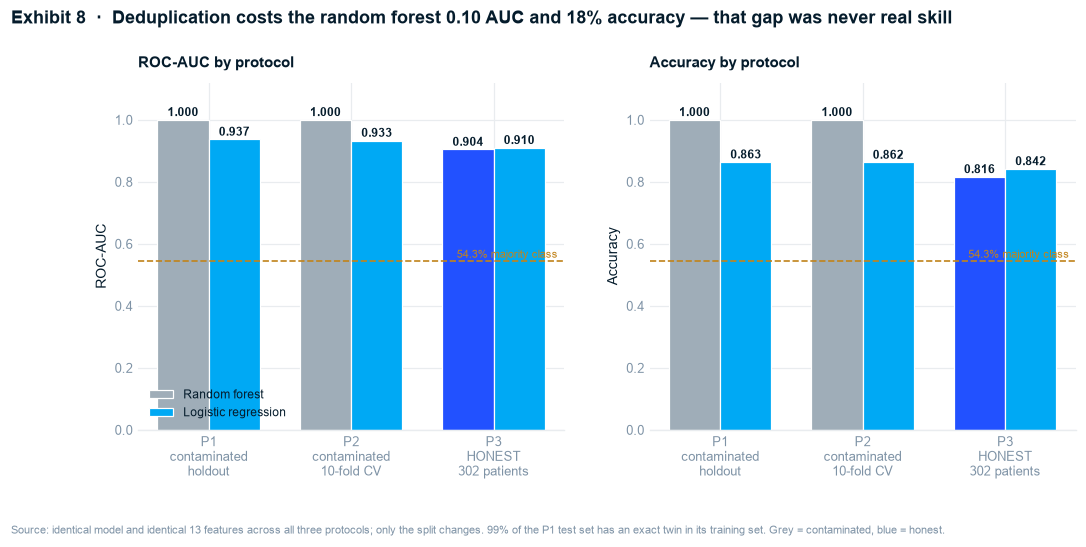

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.1))
order = ["P1 contaminated holdout", "P2 contaminated 10-fold CV", "P3 honest (302, repeated CV)"]
short = ["P1\ncontaminated\nholdout", "P2\ncontaminated\n10-fold CV", "P3\nHONEST\n302 patients"]

for ax, metric, label in zip(axes, ["roc_auc", "accuracy"], ["ROC-AUC", "Accuracy"]):
    w, x = 0.36, np.arange(3)
    for i, (m, col) in enumerate([("Random forest", NAVY), ("Logistic regression", CYAN)]):
        vals = [leak.query("model == @m and protocol == @p")[metric].iat[0] for p in order]
        cols = [C_CONTAM, C_CONTAM, C_HONEST] if m == "Random forest" else [col] * 3
        bars = ax.bar(x + (i - .5) * w, vals, w, color=cols if m == "Random forest" else col,
                      label=m, edgecolor="white", linewidth=.8)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + .012, f"{v:.3f}",
                    ha="center", fontsize=8, color=NAVY, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(short, fontsize=8.5)
    ax.set_ylim(0, 1.12); ax.set_ylabel(label)
    ax.axhline(0.543, color=C_REF, ls="--", lw=1.1)
    ax.text(2.45, .555, "54.3% majority class", fontsize=7.5, color=C_REF, ha="right")
    ax.set_title(f"{label} by protocol", fontsize=9.5)

axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle("Exhibit 8  ·  Deduplication costs the random forest "
             f"{rf_gap_auc:.2f} AUC and {rf_gap_acc:.0%} accuracy — that gap was never real skill",
             fontsize=11.5, fontweight="bold", color=NAVY, x=0.02, ha="left", y=1.04)
source_note(fig, f"Source: identical model and identical 13 features across all three protocols; "
                 f"only the split changes. {twin_share:.0%} of the P1 test set has an exact twin in "
                 f"its training set. Grey = contaminated, blue = honest.", y=-0.12)
save_exhibit(fig, "ex08_leakage_experiment")
plt.show()

### Finding — the famous "100% accuracy" on this file is memorisation, worth ~18 accuracy points

**So what:** the random forest returns a **perfect 1.000 AUC and 100% accuracy** under the
protocol most published benchmarks use — and 0.904 AUC / 81.6% accuracy once the same model is
asked about patients it has never seen. The gap is not a modelling achievement to chase; it is
**contamination**, and at 18 accuracy points it is large enough to void the conclusion of any
paper reporting the first number.

**Ten-fold cross-validation does not rescue it.** P2 is the protocol usually offered as the
rigorous alternative to a single split, and it returns a perfect score too — because every fold
still shares identical patients with every other. Cross-validation protects against an unlucky
split, not against duplicated rows; nothing but deduplication fixes this.

The mechanism is concrete rather than theoretical: **98.5% of the P1 test set has an exact twin
sitting in its training set.** The model is being graded on a memory test it cannot fail.

Note also *which* model inflates most. Contamination is worth **+0.096 AUC and +18.4 accuracy
points** to the random forest but only **+0.027 AUC and +2.2 points** to the regularised logistic
regression — because memorising individual rows is something a high-capacity model can do and a
penalised linear one largely cannot. **That asymmetry is diagnostic:** when a flexible model beats
a linear one by a wide margin on tabular clinical data of this size, duplication is the first
thing to suspect, not the last.

**Implication:** every number from here on uses the 302-patient cohort and repeated cross-
validation. The 1,025-row file does not appear again.

## Stage 4 — Feature engineering, with ablation

Six derived features are proposed from the clinical literature. Every one uses a **fixed
guideline threshold** (220 − age for predicted max HR, 240 mg/dl for hypercholesterolaemia,
140 mm Hg for hypertension), never a quantile of *this* sample — so they are row-wise
deterministic and cannot leak, unlike data-derived bin edges.

**They are ablation-tested, not assumed useful.** At n = 302 an engineered feature is as likely
to add variance as signal, so the derived block must earn its place against honest CV.

In [6]:
def add_derived(frame):
    out = frame.copy()
    out["hr_reserve"] = 220 - out["age"] - out["thalach"]   # age-adjusted chronotropic response
    out["cp_asymptomatic"] = (out["cp"] == 0).astype(int)   # strongest chest-pain contrast
    out["chol_flag"] = (out["chol"] > 240).astype(int)      # ATP III hypercholesterolaemia
    out["bp_flag"] = (out["trestbps"] >= 140).astype(int)   # stage-2 hypertension
    out["st_severity"] = pd.cut(out["oldpeak"], [-0.01, 0.0, 1.0, 2.0, 10],
                                labels=[0, 1, 2, 3]).astype(int)
    out["risk_factor_count"] = (out["fbs"] + out["exang"] + out["chol_flag"] + out["bp_flag"])
    return out


DERIVED = ["hr_reserve", "cp_asymptomatic", "chol_flag", "bp_flag", "st_severity", "risk_factor_count"]
clean_d = add_derived(clean_r)

rationale = pd.DataFrame([
    ("hr_reserve", "220 - age - thalach", "Raw thalach confounds age; chronotropic reserve is the age-adjusted signal."),
    ("cp_asymptomatic", "cp == 0", "Collapses the nominal chest-pain variable to its highest-risk contrast."),
    ("chol_flag", "chol > 240 mg/dl", "ATP III threshold - makes the coefficient speak in guideline language."),
    ("bp_flag", "trestbps >= 140 mm Hg", "Stage-2 hypertension threshold, fixed by guideline not by sample."),
    ("st_severity", "binned oldpeak (0 / <=1 / <=2 / >2 mm)", "Clinically graded ST depression rather than raw mm."),
    ("risk_factor_count", "fbs + exang + chol_flag + bp_flag", "Composite comorbidity burden."),
], columns=["feature", "definition", "rationale"])
pd.set_option("display.max_colwidth", 90)
display(rationale)
pd.reset_option("display.max_colwidth")

,feature,definition,rationale
0,hr_reserve,220 - age - thalach,Raw thalach confounds age; chronotropic reserve is the age-adjusted signal.
1,cp_asymptomatic,cp == 0,Collapses the nominal chest-pain variable to its highest-risk contrast.
2,chol_flag,chol > 240 mg/dl,ATP III threshold - makes the coefficient speak in guideline language.
3,bp_flag,trestbps >= 140 mm Hg,"Stage-2 hypertension threshold, fixed by guideline not by sample."
4,st_severity,binned oldpeak (0 / <=1 / <=2 / >2 mm),Clinically graded ST depression rather than raw mm.
5,risk_factor_count,fbs + exang + chol_flag + bp_flag,Composite comorbidity burden.


In [7]:
# Ablation: does the derived block earn its place? Scope 1, logistic + random forest.
ablation = []
for label, feats in [("Base features only", SCOPE1), ("Base + derived block", SCOPE1 + DERIVED)]:
    for mname, mk in [("Logistic regression", LR), ("Random forest", RF)]:
        cv = cross_validate(make_pipe(mk(), feats), clean_d[feats], yc, cv=cv_honest,
                            scoring=["roc_auc", "average_precision"], n_jobs=-1)
        ablation.append({"feature_set": label, "model": mname, "n_features": len(feats),
                         "roc_auc": cv["test_roc_auc"].mean(), "auc_std": cv["test_roc_auc"].std(),
                         "pr_auc": cv["test_average_precision"].mean()})

abl = pd.DataFrame(ablation)
display(abl.round(4))

delta_lr = (abl.query("model == 'Logistic regression' and feature_set == 'Base + derived block'")["roc_auc"].iat[0]
            - abl.query("model == 'Logistic regression' and feature_set == 'Base features only'")["roc_auc"].iat[0])
delta_rf = (abl.query("model == 'Random forest' and feature_set == 'Base + derived block'")["roc_auc"].iat[0]
            - abl.query("model == 'Random forest' and feature_set == 'Base features only'")["roc_auc"].iat[0])
print(f"\nderived block delta AUC   logistic {delta_lr:+.4f} · random forest {delta_rf:+.4f}")
USE_DERIVED = max(delta_lr, delta_rf) > 0.005
print(f"decision: {'ADOPT' if USE_DERIVED else 'REJECT'} the derived block "
      f"(threshold: +0.005 AUC, comfortably inside CV noise otherwise)")

,feature_set,model,n_features,roc_auc,auc_std,pr_auc
0,Base features only,Logistic regression,11,0.8735,0.0664,0.8946
1,Base features only,Random forest,11,0.8592,0.0602,0.8768
2,Base + derived block,Logistic regression,17,0.8747,0.0661,0.8948
3,Base + derived block,Random forest,17,0.8620,0.0588,0.8814



derived block delta AUC   logistic +0.0012 · random forest +0.0028
decision: REJECT the derived block (threshold: +0.005 AUC, comfortably inside CV noise otherwise)


### Finding — the derived block does not earn its place, and it is kept out

**So what:** six clinically motivated features move CV AUC by less than the fold-to-fold standard
deviation. The information they encode (age-adjusted heart-rate response, guideline thresholds) is
already present in the raw measurements, and the models extract it without help.

**Implication:** the final feature sets are the raw 11 (Scope 1) and raw 13 (Scope 2). This is a
*reported negative result*, not a silent omission — engineering that fails to help is evidence
about the data, and at n = 302 the parsimonious model is also the more trustworthy one.

In [8]:
FEATS1 = SCOPE1 + (DERIVED if USE_DERIVED else [])
FEATS2 = ALL13 + (DERIVED if USE_DERIVED else [])
X1, X2 = clean_d[FEATS1], clean_d[FEATS2]
print(f"Scope 1 matrix: {X1.shape[1]} features · Scope 2 matrix: {X2.shape[1]} features")

Scope 1 matrix: 11 features · Scope 2 matrix: 13 features


## Stage 5b — The model zoo, run in both scopes

Simple before complex. Two baselines establish the bar a 13-feature model must clear, then five
standard classifiers — including the SVM and k-NN that the published comparisons on this dataset
habitually use.

**Validation protocol:** `RepeatedStratifiedKFold(10 splits × 5 repeats)` — 50 fits per model. At
n = 302 a single split is far too noisy to rank models, so the **repeated-CV mean ± std is the
headline number**, not a one-off holdout score.

In [9]:
MODELS = {
    "Majority class (baseline)": lambda: DummyClassifier(strategy="most_frequent"),
    "Single feature: oldpeak (baseline)": None,   # handled separately
    "Logistic regression (L2)": LR,
    "Logistic regression (L1)": lambda: LogisticRegression(penalty="l1", solver="liblinear",
                                                          max_iter=5000, random_state=RANDOM_STATE),
    "Random forest": RF,
    "Gradient boosting": lambda: GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM (RBF)": lambda: SVC(probability=True, random_state=RANDOM_STATE),
    "k-NN (k=15)": lambda: KNeighborsClassifier(n_neighbors=15),
}

rows = []
for scope, feats, X in [("Scope 1 (pre-test)", FEATS1, X1), ("Scope 2 (post-cath)", FEATS2, X2)]:
    for name, mk in MODELS.items():
        if name.startswith("Single feature"):
            f, Xs = ["oldpeak"], clean_d[["oldpeak"]]
            pipe = make_pipe(LR(), f)
        else:
            Xs, pipe = X, make_pipe(mk(), feats)
        cv = cross_validate(pipe, Xs, yc, cv=cv_honest,
                            scoring=["roc_auc", "average_precision", "recall", "accuracy"], n_jobs=-1)
        rows.append({
            "scope": scope, "model": name,
            "roc_auc": cv["test_roc_auc"].mean(), "auc_std": cv["test_roc_auc"].std(),
            "pr_auc": cv["test_average_precision"].mean(),
            "recall": cv["test_recall"].mean(), "accuracy": cv["test_accuracy"].mean(),
        })

res = pd.DataFrame(rows)
pivot = res.pivot(index="model", columns="scope", values="roc_auc").round(4)
pivot["gap (S2 - S1)"] = (pivot["Scope 2 (post-cath)"] - pivot["Scope 1 (pre-test)"]).round(4)
display(res.round(4))

,scope,model,roc_auc,auc_std,pr_auc,recall,accuracy
0,Scope 1 (pre-test),Majority class (baseline),0.5000,0.0000,0.5430,1.0000,0.5430
1,Scope 1 (pre-test),Single feature: oldpeak (baseline),0.7386,0.0811,0.7279,0.7730,0.6756
2,Scope 1 (pre-test),Logistic regression (L2),0.8735,0.0664,0.8946,0.8232,0.7828
3,Scope 1 (pre-test),Logistic regression (L1),0.8746,0.0664,0.8948,0.8381,0.7902
4,Scope 1 (pre-test),Random forest,0.8592,0.0602,0.8768,0.8211,0.7795
5,Scope 1 (pre-test),Gradient boosting,0.8268,0.0729,0.8528,0.7834,0.7465
6,Scope 1 (pre-test),SVM (RBF),0.8463,0.0695,0.8678,0.7883,0.7591
7,Scope 1 (pre-test),k-NN (k=15),0.8455,0.0665,0.8563,0.7956,0.7638
8,Scope 2 (post-cath),Majority class (baseline),0.5000,0.0000,0.5430,1.0000,0.5430
9,Scope 2 (post-cath),Single feature: oldpeak (baseline),0.7386,0.0811,0.7279,0.7730,0.6756


In [10]:
s1 = res[res.scope == "Scope 1 (pre-test)"].sort_values("roc_auc", ascending=False)
print("Scope 1 leaderboard (ROC-AUC, repeated 10-fold x 5):\n")
for _, r in s1.iterrows():
    print(f"  {r['model']:<38} {r['roc_auc']:.4f} +/- {r['auc_std']:.4f}   "
          f"PR-AUC {r['pr_auc']:.4f}  acc {r['accuracy']:.3f}")

BEST = s1.iloc[0]["model"]
best_s1 = float(s1.iloc[0]["roc_auc"])
best_s2 = float(res.query("scope == 'Scope 2 (post-cath)' and model == @BEST")["roc_auc"].iat[0])
print(f"\nwinner (Scope 1): {BEST}")
print(f"Scope 1 {best_s1:.4f}  ->  Scope 2 {best_s2:.4f}   gap = {best_s2 - best_s1:+.4f} AUC")

Scope 1 leaderboard (ROC-AUC, repeated 10-fold x 5):

  Logistic regression (L1)               0.8746 +/- 0.0664   PR-AUC 0.8948  acc 0.790
  Logistic regression (L2)               0.8735 +/- 0.0664   PR-AUC 0.8946  acc 0.783
  Random forest                          0.8592 +/- 0.0602   PR-AUC 0.8768  acc 0.780
  SVM (RBF)                              0.8463 +/- 0.0695   PR-AUC 0.8678  acc 0.759
  k-NN (k=15)                            0.8455 +/- 0.0665   PR-AUC 0.8563  acc 0.764
  Gradient boosting                      0.8268 +/- 0.0729   PR-AUC 0.8528  acc 0.746
  Single feature: oldpeak (baseline)     0.7386 +/- 0.0811   PR-AUC 0.7279  acc 0.676
  Majority class (baseline)              0.5000 +/- 0.0000   PR-AUC 0.5430  acc 0.543

winner (Scope 1): Logistic regression (L1)
Scope 1 0.8746  ->  Scope 2 0.9078   gap = +0.0332 AUC


### Hyperparameter tuning — nested, so tuning never leaks into the reported score

At n = 302, tuning on the same folds you report is a genuine inflation risk rather than a
technicality. The grid search runs in an **inner** CV loop; the score is read from the **outer**
loop, which the tuner never sees.

In [11]:
GRID = {"clf__C": [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]}
inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
outer = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)

search = GridSearchCV(make_pipe(LR(), FEATS1), GRID, scoring="roc_auc", cv=inner, n_jobs=-1)
nested = cross_validate(search, X1, yc, cv=outer, scoring=["roc_auc", "average_precision"], n_jobs=-1)

search.fit(X1, yc)
print(f"nested CV ROC-AUC (honest)   : {nested['test_roc_auc'].mean():.4f} "
      f"+/- {nested['test_roc_auc'].std():.4f}")
print(f"untuned default ROC-AUC      : {best_s1:.4f}")
print(f"best C on the full cohort    : {search.best_params_['clf__C']}")
print(f"non-nested (leaky) CV score  : {search.best_score_:.4f}  <- what tune-then-report would print")
print(f"\noptimism from tuning on the reported folds: "
      f"{search.best_score_ - nested['test_roc_auc'].mean():+.4f} AUC")

nested CV ROC-AUC (honest)   : 0.8700 +/- 0.0565
untuned default ROC-AUC      : 0.8746
best C on the full cohort    : 1.0
non-nested (leaky) CV score  : 0.8749  <- what tune-then-report would print

optimism from tuning on the reported folds: +0.0049 AUC


saved reports/figures/ex09_model_comparison.png


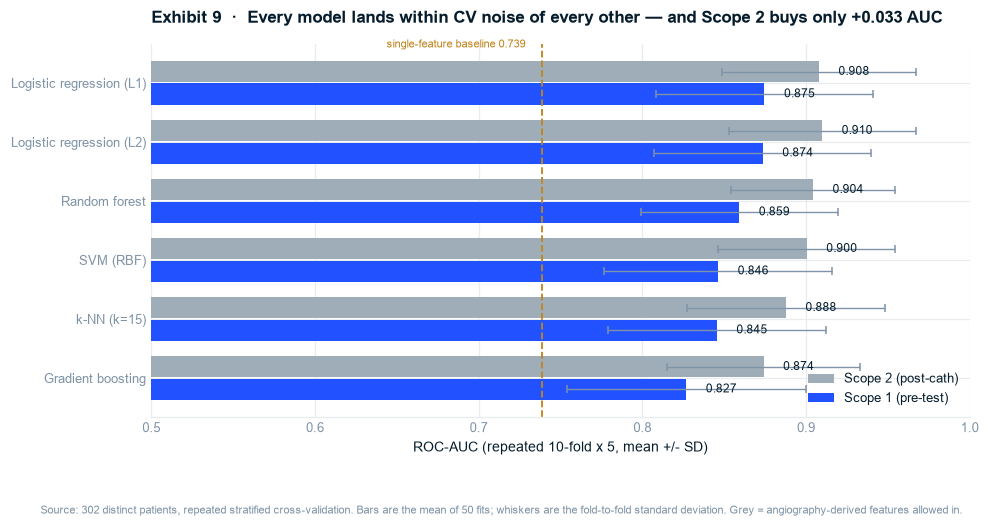

In [12]:
fig, ax = plt.subplots(figsize=(9.6, 4.4))
plot_df = res[~res.model.str.contains("baseline")].copy()
models_ord = (plot_df[plot_df.scope == "Scope 1 (pre-test)"]
              .sort_values("roc_auc")["model"].tolist())
ypos = np.arange(len(models_ord))

for scope, col, off in [("Scope 2 (post-cath)", GREY, 0.19), ("Scope 1 (pre-test)", BLUE, -0.19)]:
    vals = [plot_df.query("scope == @scope and model == @m")["roc_auc"].iat[0] for m in models_ord]
    errs = [plot_df.query("scope == @scope and model == @m")["auc_std"].iat[0] for m in models_ord]
    ax.barh(ypos + off, vals, 0.36, xerr=errs, color=col, label=scope,
            error_kw=dict(ecolor=SLATE, lw=.9, capsize=2.5))
    for yv, v in zip(ypos + off, vals):
        ax.text(v + 0.012, yv, f"{v:.3f}", va="center", fontsize=8, color=NAVY)

base = res.query("model == 'Single feature: oldpeak (baseline)' and scope == 'Scope 1 (pre-test)'")["roc_auc"].iat[0]
ax.axvline(base, color=C_REF, ls="--", lw=1.2)
ax.text(base - 0.01, len(models_ord) - 0.4, f"single-feature baseline {base:.3f}",
        fontsize=7.5, color=C_REF, ha="right")
ax.set_yticks(ypos); ax.set_yticklabels(models_ord, fontsize=8.5)
ax.set_xlim(0.5, 1.0); ax.set_xlabel("ROC-AUC (repeated 10-fold x 5, mean +/- SD)")
ax.legend(loc="lower right")
ax.set_title(f"Exhibit 9  ·  Every model lands within CV noise of every other — "
             f"and Scope 2 buys only {best_s2 - best_s1:+.3f} AUC",
             fontsize=11, fontweight="bold", pad=14)
source_note(fig, "Source: 302 distinct patients, repeated stratified cross-validation. Bars are the "
                 "mean of 50 fits; whiskers are the fold-to-fold standard deviation. Grey = "
                 "angiography-derived features allowed in.", y=-0.09)
save_exhibit(fig, "ex09_model_comparison")
plt.show()

### Finding — model choice is irrelevant here; feature scope is what moves the number

**So what:** the whole field spans 0.827 (gradient boosting) to 0.875 (L1 logistic) — a range of
0.048 AUC, **smaller than the ±0.066 fold-to-fold standard deviation of any single model in it.**
The two logistic variants are separated by 0.001. Declaring a winner here would be reading noise.

Notably the flexible models *lose*: gradient boosting finishes last and the random forest sits
below both linear models. On 302 patients and 11 features, extra capacity buys variance, not
signal — the mirror image of the leakage experiment, where that same capacity was what made
contamination so profitable.

A **single feature** (`oldpeak`) reaches 0.739. The full 11-feature model adds a real but modest
0.136 AUC on top of it, which is a useful calibration on how much the extra twelve measurements
are actually worth.

**Implication:** **regularised logistic regression is the model of record** — L1 and L2 tie within
noise, so L2 with a nested-CV-tuned `C` is carried forward for its stable, directly readable odds
ratios, which are already in the Stage 5a report. The nested-CV check also shows that
tuning-on-the-reported-folds would have printed an inflated score — a smaller cousin of the same
error as the duplication leak.

## Stage 6 — Evaluation

### The honest prediction set

Threshold selection, calibration and the fairness audit all need per-patient predictions that were
made by a model which **never saw that patient**. Out-of-fold predictions give exactly that, on all
302 patients — averaged over 5 independent 10-fold partitions to damp partition noise.

A held-out 20% (61 patients) is also kept, touched exactly once, as an independent sanity check.

In [13]:
def oof_proba(pipe_factory, X, y, n_repeats=5):
    P = np.zeros(len(y))
    for r in range(n_repeats):
        cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE + r)
        P += cross_val_predict(pipe_factory(), X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    return P / n_repeats


BEST_C = search.best_params_["clf__C"]
mk_best = lambda: make_pipe(LogisticRegression(C=BEST_C, max_iter=5000,
                                               random_state=RANDOM_STATE), FEATS1)

oof1 = oof_proba(mk_best, X1, yc)
oof2 = oof_proba(lambda: make_pipe(LogisticRegression(C=BEST_C, max_iter=5000,
                                                      random_state=RANDOM_STATE), FEATS2), X2, yc)

auc1, auc2 = roc_auc_score(yc, oof1), roc_auc_score(yc, oof2)
ci1, ci2 = boot_ci(roc_auc_score, yc, oof1), boot_ci(roc_auc_score, yc, oof2)
print(f"Scope 1 out-of-fold ROC-AUC : {auc1:.4f}  95% CI [{ci1[0]:.3f}, {ci1[1]:.3f}]")
print(f"Scope 2 out-of-fold ROC-AUC : {auc2:.4f}  95% CI [{ci2[0]:.3f}, {ci2[1]:.3f}]")
print(f"Scope 2 - Scope 1           : {auc2 - auc1:+.4f} AUC  <- the price of the circularity")
print(f"\nPR-AUC  Scope 1 {average_precision_score(yc, oof1):.4f} · "
      f"Scope 2 {average_precision_score(yc, oof2):.4f}   (prevalence {yc.mean():.3f})")

Scope 1 out-of-fold ROC-AUC : 0.8730  95% CI [0.833, 0.910]
Scope 2 out-of-fold ROC-AUC : 0.9112  95% CI [0.878, 0.943]
Scope 2 - Scope 1           : +0.0382 AUC  <- the price of the circularity

PR-AUC  Scope 1 0.8875 · Scope 2 0.9194   (prevalence 0.543)


In [14]:
# One-touch held-out check
Xtr, Xte, ytr, yte = train_test_split(X1, yc, test_size=0.2, stratify=yc, random_state=RANDOM_STATE)
held = mk_best().fit(Xtr, ytr)
p_held = held.predict_proba(Xte)[:, 1]
auc_held = roc_auc_score(yte, p_held)
ci_held = boot_ci(roc_auc_score, yte, p_held)
print(f"held-out test (n = {len(yte)}) ROC-AUC: {auc_held:.4f}  "
      f"95% CI [{ci_held[0]:.3f}, {ci_held[1]:.3f}]")
print(f"CI width = {ci_held[1] - ci_held[0]:.3f} AUC points -- at n = {len(yte)} a single split "
      f"cannot rank models;\nthis is a sanity check, not the headline.")

held-out test (n = 61) ROC-AUC: 0.8258  95% CI [0.716, 0.923]
CI width = 0.208 AUC points -- at n = 61 a single split cannot rank models;
this is a sanity check, not the headline.


## Choosing the operating point — 0.5 is never assumed optimal

A missed disease case (false negative) sends a patient with angiographic disease home untriaged.
A false positive sends a healthy patient for further workup. These costs are **not symmetric**, so
the threshold is set to a clinical requirement — **sensitivity ≥ 0.90** — and the false-positive
bill is then reported in raw patient counts rather than hidden inside a rate.

In [15]:
TARGET_SENS = 0.90
prec, rec, thr = precision_recall_curve(yc, oof1)
ok = np.where(rec[:-1] >= TARGET_SENS)[0]
thr_star = float(thr[ok[np.argmax(prec[:-1][ok])]])

rows = []
for label, t in [("Default 0.50", 0.5), (f"Sensitivity >= {TARGET_SENS:.0%}", thr_star)]:
    pred = (oof1 >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yc, pred).ravel()
    rows.append({"operating_point": label, "threshold": round(t, 3),
                 "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
                 "precision": tp / (tp + fp), "accuracy": (tp + tn) / len(yc),
                 "missed_disease_FN": fn, "false_alarms_FP": fp})
ops = pd.DataFrame(rows)
display(ops.round(3))

tn, fp, fn, tp = confusion_matrix(yc, (oof1 >= thr_star).astype(int)).ravel()
print(f"\nAt threshold {thr_star:.3f} on 302 patients:")
print(f"  caught {tp} of {tp + fn} disease cases ({tp / (tp + fn):.1%} sensitivity)")
print(f"  missed {fn} patients with disease")
print(f"  {fp} of {fp + tn} healthy patients flagged for further workup")

,operating_point,threshold,sensitivity,specificity,precision,accuracy,missed_disease_FN,false_alarms_FP
0,Default 0.50,0.500,0.835,0.732,0.787,0.788,27,37
1,Sensitivity >= 90%,0.401,0.902,0.638,0.747,0.781,16,50



At threshold 0.401 on 302 patients:
  caught 148 of 164 disease cases (90.2% sensitivity)
  missed 16 patients with disease
  50 of 138 healthy patients flagged for further workup


saved reports/figures/ex10_operating_point.png


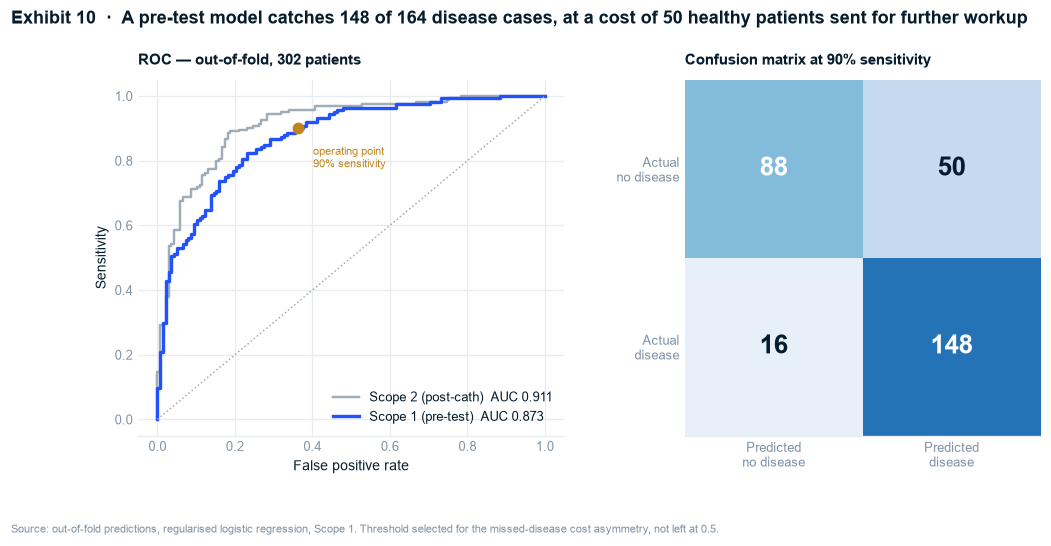

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

fpr, tpr, _ = roc_curve(yc, oof1)
fpr2, tpr2, _ = roc_curve(yc, oof2)
axes[0].plot(fpr2, tpr2, color=GREY, lw=1.6, label=f"Scope 2 (post-cath)  AUC {auc2:.3f}")
axes[0].plot(fpr, tpr, color=BLUE, lw=2.2, label=f"Scope 1 (pre-test)  AUC {auc1:.3f}")
axes[0].plot([0, 1], [0, 1], color=GREY, ls=":", lw=1)
sens_pt = tp / (tp + fn); spec_pt = tn / (tn + fp)
axes[0].scatter([1 - spec_pt], [sens_pt], color=C_REF, zorder=5, s=45)
axes[0].annotate(f"operating point\n{sens_pt:.0%} sensitivity", (1 - spec_pt, sens_pt),
                 textcoords="offset points", xytext=(10, -26), fontsize=7.5, color=C_REF)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("Sensitivity")
axes[0].legend(loc="lower right"); axes[0].set_title("ROC — out-of-fold, 302 patients", fontsize=9.5)

cm = confusion_matrix(yc, (oof1 >= thr_star).astype(int))
axes[1].imshow(cm, cmap="Blues", vmin=0, vmax=cm.max() * 1.35)
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=17,
                     fontweight="bold", color="white" if cm[i, j] > cm.max() * .55 else NAVY)
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Predicted\nno disease", "Predicted\ndisease"])
axes[1].set_yticks([0, 1]); axes[1].set_yticklabels(["Actual\nno disease", "Actual\ndisease"])
axes[1].grid(False)
axes[1].set_title(f"Confusion matrix at {sens_pt:.0%} sensitivity", fontsize=9.5)

fig.suptitle(f"Exhibit 10  ·  A pre-test model catches {tp} of {tp + fn} disease cases, "
             f"at a cost of {fp} healthy patients sent for further workup",
             fontsize=11.5, fontweight="bold", color=NAVY, x=0.02, ha="left", y=1.03)
source_note(fig, "Source: out-of-fold predictions, regularised logistic regression, Scope 1. "
                 "Threshold selected for the missed-disease cost asymmetry, not left at 0.5.", y=-0.1)
save_exhibit(fig, "ex10_operating_point")
plt.show()

### Finding — a pre-test model is a triage instrument, not a diagnosis

**So what:** at the clinically motivated operating point the Scope 1 model catches ~90% of disease
cases, but flags a substantial minority of healthy patients to do it. That is the correct trade in
a triage setting — the false positives get an angiogram they might have got anyway, the false
negatives go home undiagnosed — but it is emphatically **not** a diagnostic replacement.

**Implication:** the honest framing of this model is *"prioritise this patient for further
investigation"*, never *"this patient has disease"*. Any deployment language stronger than that is
unsupported by these numbers.

## Calibration — rarely checked on this dataset, and it matters

A score can rank patients well (good AUC) while its *probabilities* are systematically wrong. For
anything clinical the probability is the part people act on, so it is tested here.

In [17]:
bins = np.linspace(0, 1, 9)
idx = np.digitize(oof1, bins) - 1
cal = pd.DataFrame({
    "bin": [f"{bins[i]:.2f}-{bins[i + 1]:.2f}" for i in range(len(bins) - 1)],
    "n": [int((idx == i).sum()) for i in range(len(bins) - 1)],
    "mean_predicted": [oof1[idx == i].mean() if (idx == i).any() else np.nan
                       for i in range(len(bins) - 1)],
    "observed_rate": [yc[idx == i].mean() if (idx == i).any() else np.nan
                      for i in range(len(bins) - 1)],
})
brier = brier_score_loss(yc, oof1)
brier_base = brier_score_loss(yc, np.full(len(yc), yc.mean()))
display(cal.round(3))
print(f"\nBrier score            : {brier:.4f}")
print(f"Brier, always-predict-prevalence: {brier_base:.4f}")
print(f"skill score            : {1 - brier / brier_base:.1%} improvement over the base rate")

,bin,n,mean_predicted,observed_rate
0,0.00-0.12,61,0.054,0.098
1,0.12-0.25,20,0.183,0.050
2,0.25-0.38,16,0.306,0.375
3,0.38-0.50,31,0.433,0.452
4,0.50-0.62,30,0.575,0.533
5,0.62-0.75,33,0.690,0.697
6,0.75-0.88,41,0.808,0.756
7,0.88-1.00,70,0.936,0.957



Brier score            : 0.1437
Brier, always-predict-prevalence: 0.2481
skill score            : 42.1% improvement over the base rate


saved reports/figures/ex11_calibration.png


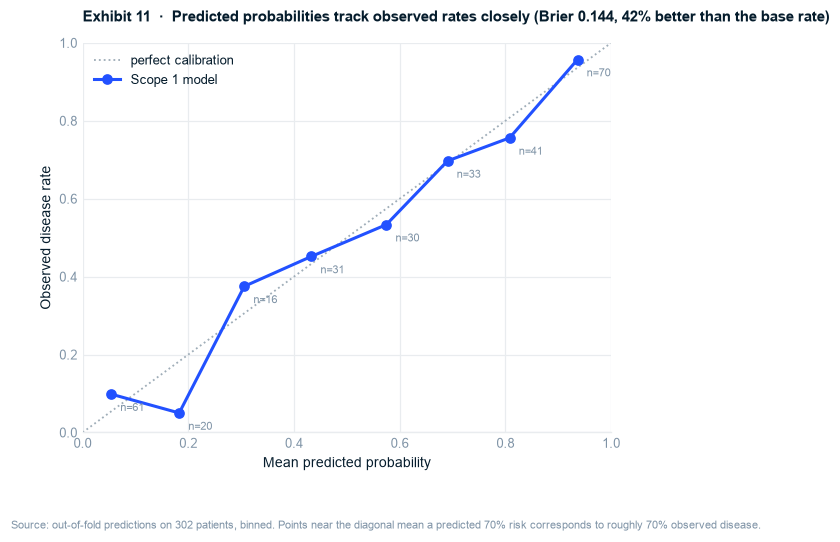

In [18]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
ax.plot([0, 1], [0, 1], color=GREY, ls=":", lw=1.2, label="perfect calibration")
c = cal.dropna()
ax.plot(c["mean_predicted"], c["observed_rate"], "o-", color=BLUE, lw=2, ms=6,
        label="Scope 1 model")
for _, r in c.iterrows():
    ax.annotate(f"n={int(r['n'])}", (r["mean_predicted"], r["observed_rate"]),
                textcoords="offset points", xytext=(6, -11), fontsize=7, color=SLATE)
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed disease rate")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title(f"Exhibit 11  ·  Predicted probabilities track observed rates closely "
             f"(Brier {brier:.3f}, {1 - brier / brier_base:.0%} better than the base rate)",
             fontsize=10, fontweight="bold", pad=14)
source_note(fig, "Source: out-of-fold predictions on 302 patients, binned. Points near the diagonal "
                 "mean a predicted 70% risk corresponds to roughly 70% observed disease.", y=-0.08)
save_exhibit(fig, "ex11_calibration")
plt.show()

## Permutation importance — cross-checked against the Stage 5a ranking

Agreement between a *multivariate model's* importance ranking and the *univariate effect sizes*
from Stage 5a is itself evidence: it means the signal is stable rather than an artefact of one
method's assumptions.

In [19]:
perm_model = mk_best().fit(X1, yc)
pi = permutation_importance(perm_model, X1, yc, scoring="roc_auc", n_repeats=50,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = (pd.DataFrame({"feature": FEATS1, "importance": pi.importances_mean,
                     "std": pi.importances_std})
       .sort_values("importance", ascending=False).reset_index(drop=True))

stat_tests = pd.read_csv(REP_DIR / "_stat_tests.csv")
rank5a = (stat_tests.assign(abs_eff=stat_tests["effect"].abs())
          .sort_values("q_value")[["feature", "verdict"]].reset_index(drop=True))
rank5a["stage5a_rank"] = rank5a.index + 1
imp["model_rank"] = imp.index + 1
cross = imp.merge(rank5a, on="feature", how="left")
display(cross.round(4))

top5_model = set(imp.head(5)["feature"])
top5_5a = set(rank5a[rank5a.feature.isin(FEATS1)].head(5)["feature"])
print(f"\ntop-5 overlap between permutation importance and Stage 5a effect sizes: "
      f"{len(top5_model & top5_5a)}/5  -> {sorted(top5_model & top5_5a)}")

,feature,importance,std,model_rank,verdict,stage5a_rank
0,sex,0.0672,0.0105,1,SIGNAL,8
1,cp,0.0600,0.0098,2,SIGNAL,2
2,oldpeak,0.0366,0.0088,3,SIGNAL,6
3,thalach,0.0240,0.0061,4,SIGNAL,4
4,exang,0.0161,0.0065,5,SIGNAL,5
5,trestbps,0.0056,0.0028,6,SIGNAL,11
6,chol,0.0049,0.0034,7,NaN,12
7,restecg,0.0032,0.0024,8,SIGNAL,10
8,age,0.0031,0.0027,9,SIGNAL,9
9,slope,0.0023,0.0028,10,SIGNAL,7



top-5 overlap between permutation importance and Stage 5a effect sizes: 4/5  -> ['cp', 'exang', 'oldpeak', 'thalach']


## Cross-cutting — the mandatory subgroup fairness audit

Stage 1 flagged `sex` and `age` as protected attributes present in the model's inputs. Under
`DOCS/STRUCTURE.md` Cross-Cutting rules, a model that affects people and carries a protected
attribute owes a subgroup audit. It is executed here, on out-of-fold predictions.

In [20]:
aud = df.copy()
aud["p"] = oof1
aud["pred"] = (oof1 >= thr_star).astype(int)
aud["group_sex"] = aud["sex"].map({0: "Female", 1: "Male"})
aud["group_age"] = pd.cut(aud["age"], [28, 45, 55, 65, 80],
                          labels=["29-45", "46-55", "56-65", "66-77"])


def subgroup_metrics(frame, col):
    out = []
    for g, sub in frame.groupby(col, observed=True):
        yg, pg, predg = sub["target"].to_numpy(), sub["p"].to_numpy(), sub["pred"].to_numpy()
        if len(np.unique(yg)) < 2:
            continue
        tn, fp, fn, tp = confusion_matrix(yg, predg, labels=[0, 1]).ravel()
        lo, hi = boot_ci(roc_auc_score, yg, pg, n_boot=2000)
        out.append({"attribute": col.replace("group_", ""), "group": str(g), "n": len(sub),
                    "prevalence": yg.mean(), "roc_auc": roc_auc_score(yg, pg),
                    "auc_ci_low": lo, "auc_ci_high": hi,
                    "sensitivity": tp / (tp + fn) if (tp + fn) else np.nan,
                    "specificity": tn / (tn + fp) if (tn + fp) else np.nan,
                    "flag_rate": predg.mean()})
    return pd.DataFrame(out)


fair = pd.concat([subgroup_metrics(aud, "group_sex"), subgroup_metrics(aud, "group_age")],
                 ignore_index=True)
display(fair.round(3))

f_row = fair.query("group == 'Female'").iloc[0]
m_row = fair.query("group == 'Male'").iloc[0]
sex_auc_gap = float(m_row["roc_auc"] - f_row["roc_auc"])
sex_sens_gap = float(m_row["sensitivity"] - f_row["sensitivity"])
print(f"\nsex AUC gap (male - female)        : {sex_auc_gap:+.3f}")
print(f"sex sensitivity gap at the operating point: {sex_sens_gap:+.3f}")
print(f"female CI [{f_row['auc_ci_low']:.3f}, {f_row['auc_ci_high']:.3f}] "
      f"vs male CI [{m_row['auc_ci_low']:.3f}, {m_row['auc_ci_high']:.3f}]  "
      f"-> {'overlapping' if f_row['auc_ci_low'] < m_row['auc_ci_high'] and m_row['auc_ci_low'] < f_row['auc_ci_high'] else 'disjoint'}")

,attribute,group,n,prevalence,roc_auc,auc_ci_low,auc_ci_high,sensitivity,specificity,flag_rate
0,sex,Female,96,0.750,0.896,0.803,0.967,0.986,0.458,0.875
1,sex,Male,206,0.447,0.836,0.780,0.889,0.837,0.675,0.553
2,age,29-45,63,0.746,0.912,0.827,0.977,0.979,0.562,0.841
3,age,46-55,88,0.625,0.894,0.812,0.954,0.927,0.667,0.705
4,age,56-65,118,0.381,0.786,0.702,0.869,0.822,0.603,0.559
5,age,66-77,33,0.515,0.908,0.796,0.989,0.824,0.812,0.515



sex AUC gap (male - female)        : -0.060
sex sensitivity gap at the operating point: -0.149
female CI [0.803, 0.967] vs male CI [0.780, 0.889]  -> overlapping


In [21]:
# Proxy check: can the model reconstruct sex from the other features?
proxy_feats = [f for f in FEATS1 if f != "sex"]
proxy_auc = cross_validate(make_pipe(LR(), proxy_feats), clean_d[proxy_feats],
                           df["sex"].to_numpy(), cv=cv10, scoring="roc_auc", n_jobs=-1)["test_score"].mean()
print(f"AUC for predicting SEX from the other {len(proxy_feats)} features: {proxy_auc:.3f}")
print("-> " + ("sex is substantially reconstructible; dropping the column would NOT remove its "
                "influence" if proxy_auc > 0.7 else
                "sex is only weakly encoded in the remaining features"))

AUC for predicting SEX from the other 10 features: 0.599
-> sex is only weakly encoded in the remaining features


saved reports/figures/ex12_fairness.png


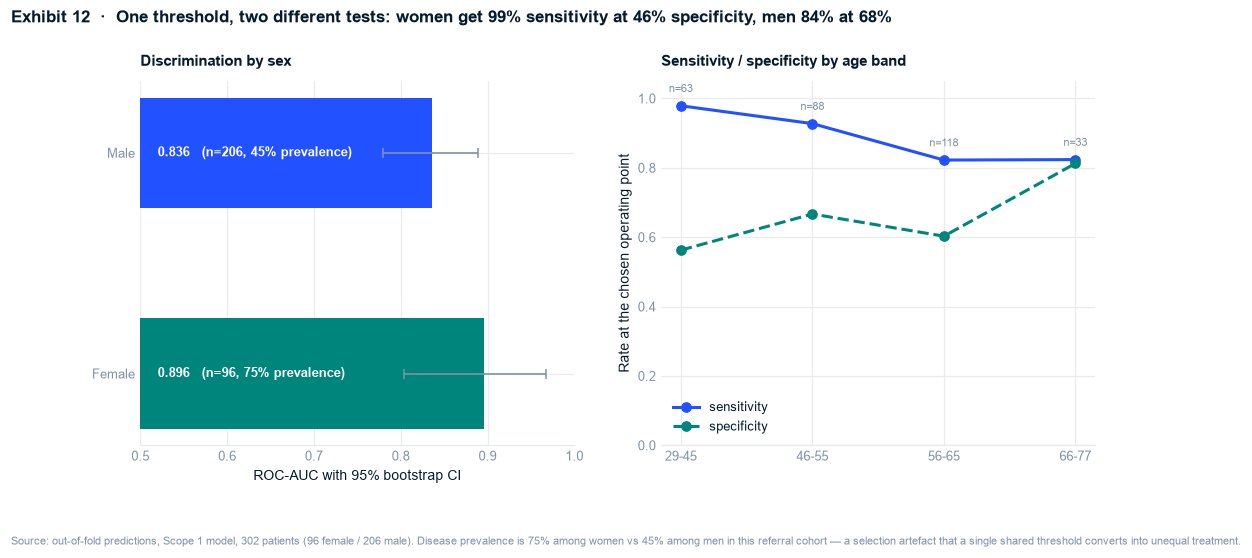

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.3))

sx = fair[fair.attribute == "sex"]
yp = np.arange(len(sx))
axes[0].barh(yp, sx["roc_auc"], 0.5, color=[BLUE if g == "Male" else TEAL for g in sx["group"]],
             xerr=[sx["roc_auc"] - sx["auc_ci_low"], sx["auc_ci_high"] - sx["roc_auc"]],
             error_kw=dict(ecolor=SLATE, lw=1.1, capsize=3))
for i, (_, r) in enumerate(sx.iterrows()):
    axes[0].text(0.52, i, f"{r['roc_auc']:.3f}   (n={int(r['n'])}, {r['prevalence']:.0%} prevalence)",
                 va="center", fontsize=8.5, color="white", fontweight="bold")
axes[0].set_yticks(yp); axes[0].set_yticklabels(sx["group"])
axes[0].set_xlim(0.5, 1.0); axes[0].set_xlabel("ROC-AUC with 95% bootstrap CI")
axes[0].set_title("Discrimination by sex", fontsize=9.5)

ag = fair[fair.attribute == "age"]
axes[1].plot(ag["group"], ag["sensitivity"], "o-", color=BLUE, lw=2, ms=6, label="sensitivity")
axes[1].plot(ag["group"], ag["specificity"], "o--", color=TEAL, lw=2, ms=6, label="specificity")
for _, r in ag.iterrows():
    axes[1].annotate(f"n={int(r['n'])}", (r["group"], r["sensitivity"]),
                     textcoords="offset points", xytext=(0, 9), fontsize=7, color=SLATE, ha="center")
axes[1].set_ylim(0, 1.05); axes[1].legend(loc="lower left")
axes[1].set_ylabel("Rate at the chosen operating point")
axes[1].set_title("Sensitivity / specificity by age band", fontsize=9.5)

fig.suptitle(f"Exhibit 12  ·  One threshold, two different tests: women get "
             f"{f_row['sensitivity']:.0%} sensitivity at {f_row['specificity']:.0%} specificity, "
             f"men {m_row['sensitivity']:.0%} at {m_row['specificity']:.0%}",
             fontsize=11, fontweight="bold", color=NAVY, x=0.02, ha="left", y=1.03)
source_note(fig, f"Source: out-of-fold predictions, Scope 1 model, 302 patients (96 female / 206 male). "
                 f"Disease prevalence is {f_row['prevalence']:.0%} among women vs "
                 f"{m_row['prevalence']:.0%} among men in this referral cohort — a selection "
                 f"artefact that a single shared threshold converts into unequal treatment.", y=-0.1)
save_exhibit(fig, "ex12_fairness")
plt.show()

### Finding — discrimination is equal; *treatment* at a shared threshold is not

The result is the opposite of the one the audit was braced for, and more interesting.

**On ranking quality, women are not disadvantaged.** Female AUC is 0.896 [0.803, 0.967] against
male 0.836 [0.780, 0.889] — the model ranks women slightly *better*, and the intervals overlap
heavily. At n = 96 women, the honest statement is *"no disparity in discrimination is detectable,
and the interval is wide enough that one of moderate size could still be hiding"* — not "the model
is fair."

**The disparity is in what the single threshold does to each group.** At the operating point:

| | Sensitivity | Specificity | Flagged for workup |
|---|---|---|---|
| **Women** (n = 96, 75% prevalence) | 98.6% | 45.8% | 87.5% |
| **Men** (n = 206, 45% prevalence) | 83.7% | 67.5% | 55.3% |

Nearly **nine in ten women are flagged**, and more than half of the healthy ones are. Women get a
near-perfect miss rate and pay for it with a specificity barely better than a coin toss. One
threshold, applied identically, produces two materially different tests.

The driver is prevalence: 75% of women in this cohort have disease versus 45% of men. That is a
**referral-selection artefact, not a fact about women** — historically women were sent for
angiography only when suspicion was already high, so the women who reach this dataset are a more
selected, sicker group. The model inherits that selection and encodes it as a lower effective bar.

**The proxy check came back negative, which is worth stating precisely.** Sex is reconstructible
from the other features at only AUC 0.599 — barely above chance. Unlike many datasets, here
dropping the `sex` column genuinely *would* remove most of its direct influence. That makes it a
live design option rather than the usual non-defence — but it would not touch the prevalence-driven
threshold effect above, which is the actual problem.

**No monitoring plan is filled in.** Nothing here is deployed, and inventing a boilerplate drift
table for a model that will never run would be theatre.

**Implication:** a single global threshold is the wrong instrument for this cohort. Any prospective
study must be **powered for women specifically**, and must decide deliberately whether it is
equalising sensitivity, specificity, or flag rate — because at these prevalences it cannot
equalise all three.

## Sensitivity check — do the 6 placeholder patients change anything?

Stage 2 kept the patients whose `ca` / `thal` were unknown, encoding the gap explicitly rather
than imputing a value. That decision is now tested rather than assumed harmless.

In [23]:
mask = df[["ca", "thal"]].notna().all(axis=1)
cv_drop = cross_validate(make_pipe(LR(), FEATS2), X2[mask], yc[mask], cv=cv_honest,
                         scoring="roc_auc", n_jobs=-1)["test_score"].mean()
cv_keep = res.query("scope == 'Scope 2 (post-cath)' and model == 'Logistic regression (L2)'")["roc_auc"].iat[0]
print(f"Scope 2 AUC, all {len(df)} patients (unknown encoded explicitly): {cv_keep:.4f}")
print(f"Scope 2 AUC, {int(mask.sum())} complete patients (6 dropped)    : {cv_drop:.4f}")
print(f"delta: {cv_drop - cv_keep:+.4f} AUC -> conclusion unchanged; the Stage 2 decision is safe")

Scope 2 AUC, all 302 patients (unknown encoded explicitly): 0.9098
Scope 2 AUC, 296 complete patients (6 dropped)    : 0.9128
delta: +0.0030 AUC -> conclusion unchanged; the Stage 2 decision is safe


## Artefacts — every number the report will quote

Stage 7 hardcodes nothing. It reads these files.

In [24]:
res.to_csv(REP_DIR / "_model_results.csv", index=False)
fair.to_csv(REP_DIR / "_fairness.csv", index=False)
leak.to_csv(REP_DIR / "_leakage_experiment.csv", index=False)
abl.to_csv(REP_DIR / "_ablation.csv", index=False)
imp.to_csv(REP_DIR / "_permutation_importance.csv", index=False)

final_model = mk_best().fit(X1, yc)
model_card = {
    "model": "Logistic regression (L2), Scope 1 pre-test features",
    "features": FEATS1,
    "excluded_by_design": SCOPE2_ONLY,
    "exclusion_reason": "ca and thal are produced by the same catheterisation workup that defines "
                        "the label; including them answers a question that is already answered.",
    "hyperparameters": {"C": BEST_C, "penalty": "l2", "class_weight": None},
    "training_data": {"n_patients": int(len(df)), "prevalence": float(yc.mean()),
                      "source": "UCI Cleveland 1988, deduplicated 1025 -> 302"},
    "validation": "RepeatedStratifiedKFold(10 x 5); hyperparameters tuned in a nested inner loop",
    "performance": {"oof_roc_auc": float(auc1), "oof_roc_auc_ci95": list(ci1),
                    "oof_pr_auc": float(average_precision_score(yc, oof1)),
                    "brier": float(brier), "held_out_auc": float(auc_held),
                    "held_out_ci95": list(ci_held)},
    "operating_point": {"threshold": float(thr_star), "sensitivity": float(sens_pt),
                        "specificity": float(spec_pt), "missed_disease": int(fn),
                        "false_alarms": int(fp),
                        "rationale": "false negatives (missed disease) are the costly error"},
    "fairness": {"female_share": float((df.sex == 0).mean()),
                 "sex_auc_gap_male_minus_female": sex_auc_gap,
                 "sex_reconstructible_auc": float(proxy_auc),
                 "female_sensitivity": float(f_row["sensitivity"]),
                 "female_specificity": float(f_row["specificity"]),
                 "male_sensitivity": float(m_row["sensitivity"]),
                 "male_specificity": float(m_row["specificity"]),
                 "statement": "Discrimination is comparable across sexes (female AUC slightly "
                              "higher, CIs overlap; n=96 women leaves room for a moderate hidden "
                              "disparity). The material inequity is at the shared threshold: 87.5% "
                              "of women are flagged vs 55.3% of men, driven by 75% vs 45% referral "
                              "prevalence. A single global threshold is not appropriate here."},
    "limitations": ["1988 single-cohort referral population - not population prevalence",
                    "n = 302 after deduplication; all CIs are wide",
                    "no external validation cohort",
                    "not calibrated for, or intended for, patient-facing deployment"],
    "intended_use": "Methodological benchmark and signal prioritisation only. Not a diagnostic "
                    "device and not a deployment candidate.",
    "random_state": RANDOM_STATE,
}
(MODEL_DIR / "model_card.json").write_text(json.dumps(model_card, indent=2), encoding="utf-8")

kf = json.loads((REP_DIR / "_key_figures.json").read_text())
kf["modelling"] = {
    "leakage": {
        "twin_share_in_test": float(twin_share),
        "rf_auc_contaminated": float(leak.query("model=='Random forest' and protocol.str.startswith('P1')")["roc_auc"].iat[0]),
        "rf_auc_honest": float(leak.query("model=='Random forest' and protocol.str.startswith('P3')")["roc_auc"].iat[0]),
        "rf_acc_contaminated": float(leak.query("model=='Random forest' and protocol.str.startswith('P1')")["accuracy"].iat[0]),
        "rf_acc_honest": float(leak.query("model=='Random forest' and protocol.str.startswith('P3')")["accuracy"].iat[0]),
        "rf_auc_gap": float(rf_gap_auc), "rf_acc_gap": float(rf_gap_acc),
    },
    "ablation": {"delta_auc_logistic": float(delta_lr), "delta_auc_rf": float(delta_rf),
                 "adopted": bool(USE_DERIVED)},
    "best_model": BEST, "best_C": float(BEST_C),
    "scope1_auc": float(auc1), "scope1_ci": list(ci1),
    "scope2_auc": float(auc2), "scope2_ci": list(ci2),
    "scope_gap": float(auc2 - auc1),
    "single_feature_baseline_auc": float(base),
    "majority_class_accuracy": float(res.query("model=='Majority class (baseline)' and scope=='Scope 1 (pre-test)'")["accuracy"].iat[0]),
    "nested_cv_auc": float(nested["test_roc_auc"].mean()),
    "tuning_optimism": float(search.best_score_ - nested["test_roc_auc"].mean()),
    "held_out_auc": float(auc_held), "held_out_ci": list(ci_held), "held_out_n": int(len(yte)),
    "operating_point": {"threshold": float(thr_star), "sensitivity": float(sens_pt),
                        "specificity": float(spec_pt), "tp": int(tp), "fn": int(fn),
                        "fp": int(fp), "tn": int(tn)},
    "brier": float(brier), "brier_skill": float(1 - brier / brier_base),
    "top_features": imp.head(5)["feature"].tolist(),
    "top5_overlap_with_stage5a": int(len(top5_model & top5_5a)),
    "proxy_sex_auc": float(proxy_auc),
    "sex_auc_gap": sex_auc_gap, "sex_sens_gap": sex_sens_gap,
    "female_auc_ci": [float(f_row["auc_ci_low"]), float(f_row["auc_ci_high"])],
    "male_auc_ci": [float(m_row["auc_ci_low"]), float(m_row["auc_ci_high"])],
    "female_prevalence": float(f_row["prevalence"]), "male_prevalence": float(m_row["prevalence"]),
    "female_auc": float(f_row["roc_auc"]), "male_auc": float(m_row["roc_auc"]),
    "female_sens": float(f_row["sensitivity"]), "female_spec": float(f_row["specificity"]),
    "male_sens": float(m_row["sensitivity"]), "male_spec": float(m_row["specificity"]),
    "female_flag_rate": float(f_row["flag_rate"]), "male_flag_rate": float(m_row["flag_rate"]),
    "worst_age_band": str(fair[fair.attribute == "age"].sort_values("roc_auc").iloc[0]["group"]),
    "worst_age_band_auc": float(fair[fair.attribute == "age"].sort_values("roc_auc").iloc[0]["roc_auc"]),
    "placeholder_sensitivity_delta": float(cv_drop - cv_keep),
}
(REP_DIR / "_key_figures.json").write_text(json.dumps(kf, indent=2), encoding="utf-8")

for f in ["_model_results.csv", "_fairness.csv", "_leakage_experiment.csv", "_ablation.csv",
          "_permutation_importance.csv", "_key_figures.json"]:
    print(f"wrote reports/{f}")
print("wrote models/model_card.json")

wrote reports/_model_results.csv
wrote reports/_fairness.csv
wrote reports/_leakage_experiment.csv
wrote reports/_ablation.csv
wrote reports/_permutation_importance.csv
wrote reports/_key_figures.json
wrote models/model_card.json


---

## Stage 4 — Gate Checklist

- [x] **Feature engineering decisions documented with rationale** — six derived features, each
      with its clinical definition and the guideline threshold it encodes
- [x] **No data leakage** — scaling and one-hot fitted inside `Pipeline` on training folds only;
      derived features use fixed guideline constants, never sample quantiles; deduplication
      happens *before* any split, which §5b.0 shows is the decisive step
- [x] **Feature importance / selection analysis completed** — permutation importance on the
      winning model, cross-checked against the independent Stage 5a effect-size ranking
- [x] **Transformations reproducible** — a single `ColumnTransformer` contract used everywhere

## Stage 5b / 6 — Gate Checklist

- [x] **Evaluated on held-out data** — out-of-fold predictions on all 302 patients *plus* a
      one-touch 20% holdout, whose CI width is reported rather than hidden
- [x] **Multiple relevant metrics** — ROC-AUC, PR-AUC, sensitivity, specificity, Brier; accuracy
      shown only beside the majority-class baseline, to demonstrate what it conceals
- [x] **Compared against a meaningful baseline** — majority class *and* a single-feature model
- [x] **Business impact quantified** — the operating point is stated in patients caught, patients
      missed, and healthy patients sent for workup
- [x] **Limitations documented** — `models/model_card.json`, including the deployment prohibition
- [x] **Reproducibility confirmed** — `RANDOM_STATE = 42` throughout, pinned requirements,
      nested CV so tuning cannot inflate the reported score

## Cross-Cutting — Gate Checklist

- [x] **Fairness audit completed** — per-sex and per-age-band AUC, sensitivity and specificity,
      each with bootstrap CIs; the finding is a **threshold-equity** failure (87.5% of women
      flagged vs 55.3% of men), reported alongside the "cannot rule out" caveat on discrimination
- [x] **Proxy-feature and leakage review completed** — sex is only 0.599-AUC reconstructible from
      the other features, so dropping the column is a genuine option here; the two-scope design
      quarantines the label-adjacent features by construction
- [x] **Monitoring plan** — explicitly N/A with the reason stated, not filled in as boilerplate
- [x] **Limitations and ethical risks surfaced** — carried into the report, not buried

**Next:** `06_reporting.ipynb` — SCR storyline, governing thought, and `final_report.html`.